
<div style="background-color: Yellow; padding: 20px; text-align: center">
    <h2><b>Data Pro Project 1 Presentation</b></h2>
    <h1><b>ꕥ   Customer Churn Prediction   ꕥ  </b></h1>
    <h2>   Machine Learning Classification Models with Scikit-learn Library </h2>
    <h3>🎓 Maliheh Mahdavi Sefat - ID11408 </h3>  
    <h3>🎓 Gonçalo Costa Valente - ID12600 </h3>
    <h3>🎓 Diogo Filipe Silva Azevedo - PG63323 </h3>
    <h3>🎓 Paula Patrícia Vieira Pereira - A109027 </h3>
    <h3>🎓 Murilo Melnek Pedro - PG59343 </h3>
    <p>University of Minho</p>
    <p>School of Management, Economics, and Political Science</p>
    <p>October 2026</p>
</div>




---

<div style="background-color: maroon;color:white; padding: 20px">
<h2>What is Churn?</h2>
<h3>In a business context, <b>churn rate</b> measures the percentage of customers who stop using a company's product or service. </h3>
<h3>It is crutial for subscription based businesses to monitor customer retention and satisfaction.</h3>
</div>

---



<div style="background-color: black;color:white; padding: 20px">
<h2>1- Mount the Drive (only in Google Colab environment)</h2>
</div>

In [3]:
# only in google collab
# from google.colab import drive
# drive.mount('/drive')

<div style="background-color: black;color:white; padding: 20px">
<h2>2- Import modules and libraries and modules</h2>
</div>

In [4]:
# Importing necessary libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay


<div style="background-color: black;color:white; padding: 20px">
<h2>3- Download the Dataset from Kaggle:</h2>
<a href="https://www.kaggle.com/datasets/blastchar/telco-customer-churn" target="_blank"><b>Telco Customer Churn Dataset</b></a>
    <p>Load the dataset by Pandas</p>
</div>

In [5]:
import os

# Change directory to the notebook folder
# os.chdir('/drive/MyDrive/Project1_datapro_ML')

# Load dataset
import pandas as pd
file_path = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
churndf = pd.read_csv(file_path)
churndf.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<div style="background-color: black;color:white; padding: 20px">


<h2>4- Explore the data</h2>
</div>

In [6]:
# list of columns
churndf.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [7]:
# dataset information
churndf.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [8]:
# statistical description only works on numerical data
churndf.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [9]:
# Display unique values for each column
for col in churndf.columns:
    print("="*50)
    print(churndf[col].value_counts())
    print(churndf[col].unique()[:5],"\n")

customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64
<StringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU']
Length: 5, dtype: str 

gender
Male      3555
Female    3488
Name: count, dtype: int64
<StringArray>
['Female', 'Male']
Length: 2, dtype: str 

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64
[0 1] 

Partner
No     3641
Yes    3402
Name: count, dtype: int64
<StringArray>
['Yes', 'No']
Length: 2, dtype: str 

Dependents
No     4933
Yes    2110
Name: count, dtype: int64
<StringArray>
['No', 'Yes']
Length: 2, dtype: str 

tenure
1     613
72    362
2     238
3     200
4     176
     ... 
28     57
39     56
44     51
36     50
0      11
Name: count, Length: 73, dtype: int64
[ 1 34  2 45  8] 

PhoneService
Yes    6361
No      682
Name: count, dtype: int64
<StringArray>
['



<div style="background-color: khaki;color:black; padding: 20px">

<h3>The "TotalCharge" should not be object, as it is clearly continuous numbers with decimals. But because it had been saved with quotation marks, it is treated as string and the datatype shows object.</h3>
</div>



<div style="background-color: beige;color:black; padding: 20px">

<h3>Some values in the TotalCharch were saved as empty strings, like '  '. After conversion to numeric, they appear as missing values.</h3>
</div>

<div style="background-color: black;color:white; padding: 10px;">
<h2> 5- Preprocessing </h2>

</div>

In [10]:
# check the datatype of TotalCharges
churndf["TotalCharges"].dtype

<StringDtype(storage='python', na_value=nan)>

In [11]:
# convert object to numbers
churndf["TotalCharges"] = pd.to_numeric(
    churndf["TotalCharges"],
    errors="coerce"
)

In [12]:
# Which column has missing values?
churndf.isnull().sum()


customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

<div style="background-color: khaki;color:black; padding: 10px;">
<h2> Imputation Starategy: Mean or Median? </h2>

</div>

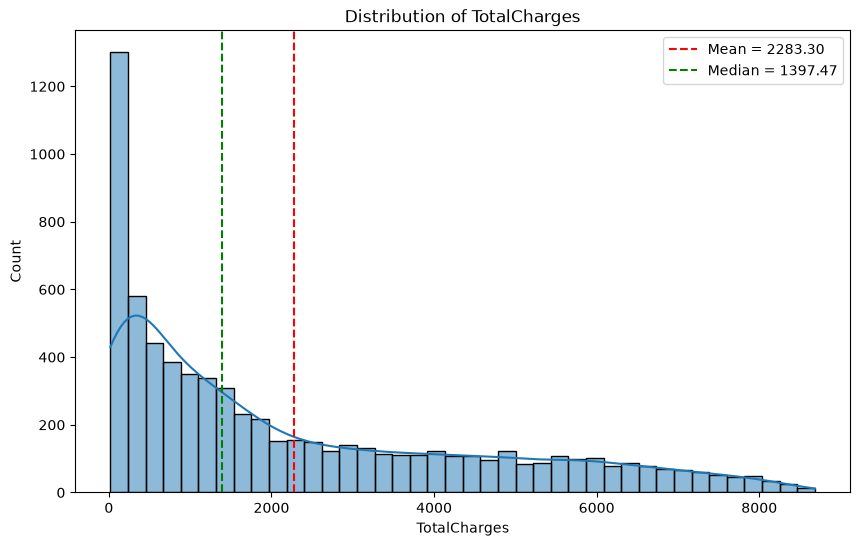

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

mean_val = churndf["TotalCharges"].mean()
median_val = churndf["TotalCharges"].median()

# plot a histogram with vertical lines for the mean and median
plt.figure(figsize=(10, 6))
sns.histplot(churndf["TotalCharges"], bins=40, kde=True)

plt.axvline(mean_val, color="red", linestyle="--", label=f"Mean = {mean_val:.2f}")
plt.axvline(median_val, color="green", linestyle="--", label=f"Median = {median_val:.2f}")

plt.title("Distribution of TotalCharges")
plt.xlabel("TotalCharges")
plt.ylabel("Count")
plt.legend()
plt.show()

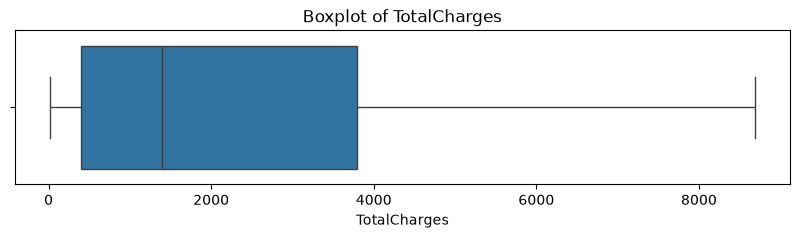

In [14]:
# plot a boxplot to check for skewness and outliers
plt.figure(figsize=(10, 2))
sns.boxplot(x=churndf["TotalCharges"])
plt.title("Boxplot of TotalCharges")
plt.show()

We chose median because it seems more representative of the real data.

In [15]:
# impute missing values of TotalCharges with median
churndf.fillna({"TotalCharges":median_val}, inplace=True)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes




<div style="background-color: khaki;color:black; padding: 20px">
<h3>There are some object columns that contain data such as 'Yes', 'No', and sometimes 'No...Service'</h3>
</div>


In [16]:
# Finding columns with 'Yes' and 'No' values
yes_no = [col for col in churndf.columns if set(['Yes', 'No']).issubset(churndf[col].unique())]
yes_no

['Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'PaperlessBilling',
 'Churn']

In [17]:
# Map 'Yes' to 1, 'No' to 0, 'No ... Service' to -1
churndf[yes_no] = churndf[yes_no].map(lambda x: 1 if x == 'Yes' else (0 if x == 'No' else -1))

churndf.head(3)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,1,0,1,0,-1,DSL,0,...,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,0,0,34,1,0,DSL,1,...,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,0,0,2,1,0,DSL,1,...,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,1


<div style="background-color: khaki;color:black; padding: 10px;"> <h2><b>LabelEncoder</b> is usually used for assigning numbers to class lables. It is useful for Likert Scale data.</h2>
    <p></p>
    <p>"very good"  →  0</p>
    <p>"good"       →  1</p>
    <p>"normal"     →  2</p>
    <p>"bad"        →  3</p>
    <p>"very bad"   →  4</p>
</div>


In [18]:
# Lable Encoding is usually used for class lables
from sklearn.preprocessing import LabelEncoder

# Initialize LabelEncoder
le = LabelEncoder()
# Apply LabelEncoder to the gender column
churndf['gender'] = le.fit_transform(churndf['gender'])
# chack the change
churndf.head(2)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,0,0,1,0,1,0,-1,DSL,0,...,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0
1,5575-GNVDE,1,0,0,0,34,1,0,DSL,1,...,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0


<div style="background-color: black;color:white; padding: 20px">

<h2>6- Splitting</h2>
</div>



<div style="background-color: khaki;color:black; padding: 20px">
<h3>We kept costumerID in the dataset to perhaps use it in relational tables of SQL, but it is not usefull in training the model. It also contains too many uniques values for converting to dummies. </h3>
</div>


In [19]:
# Determining target and features
X = churndf.drop(['customerID','Churn'], axis=1)  # feature matrix
y = churndf['Churn']                              # lable vector

In [20]:
# Encode categorical variables
X = pd.get_dummies(X, drop_first=True)

# Display the first few rows of the cleaned, preprocessed feature matrix
X.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,PaperlessBilling,MonthlyCharges,TotalCharges,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,-1,0,1,0,...,1,29.85,29.85,False,False,False,False,False,True,False
1,1,0,0,0,34,1,0,1,0,1,...,0,56.95,1889.50,False,False,True,False,False,False,True
2,1,0,0,0,2,1,0,1,1,0,...,1,53.85,108.15,False,False,False,False,False,False,True
3,1,0,0,0,45,0,-1,1,0,1,...,0,42.30,1840.75,False,False,True,False,False,False,False
4,0,0,0,0,2,1,0,0,0,0,...,1,70.70,151.65,True,False,False,False,False,True,False


**At this point we have feature matrix X and target vector y that we can use later.**

In [21]:
# check new columns in X
X.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'PaperlessBilling', 'MonthlyCharges', 'TotalCharges',
       'InternetService_Fiber optic', 'InternetService_No',
       'Contract_One year', 'Contract_Two year',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'],
      dtype='str')

In [22]:
# Splitting the dataset into train and test portions
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify= y)

<div style="background-color: black;color:white; padding: 20px">

<h2>7- Scaling</h2>
</div>



<div style="background-color: khaki;color:black; padding: 20px">
<h3>Scaling ensures that all features contribute equally to the model, avoiding bias toward features with larger ranges. It improves convergence speed and performance, especially for algorithms sensitive to feature magnitude, like Logistic Regression or SVM.</h3>
</div>


In [23]:
# scale the data
from sklearn.preprocessing import StandardScaler
# Initialize the scaler
scaler = StandardScaler()

# Fit and transform the training data
X_train = scaler.fit_transform(X_train)

# Transform the test data using the same scaler
X_test = scaler.transform(X_test)

<div style="background-color: black; color:white; padding: 20px">

<h2>8- Model training</h2>
</div>

In [24]:
from sklearn.metrics import accuracy_score, classification_report

# Initialize and train the logistic regression model
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

# Predict on the test set
y_pred = logreg.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")
print(classification_report(y_test, y_pred, target_names=['No churn', 'churn']))


Accuracy: 80.77%
              precision    recall  f1-score   support

    No churn       0.85      0.89      0.87      1035
       churn       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



<div style=" background-color: beige; padding: 10px;">
<p>The prediction results include: </p>

> <p><b>True Negatives  - False Positives</b></p>
> <p><b>False Negatives - True Positives</b></p>

<p>From which the performance metrics are calculated:</p>

<ul>         
    <li><b>Accuracy: </b> The proportion of all correctly classified cases.<b> =(TP+TN)/(TP+TN+FP+FN)</b></li>
    <li><b>Precision: </b> The proportion of correctly predicted positive observations out of all predicted positives.
        <b>= TP/(TP+FP)</b></li>
    <li><b>Recall: </b> The proportion of correctly predicted positive observations out of all actual positives. <b> =TP/(TP+FN)</b></li>
    <li><b>F1-score: </b> The harmonic mean of precision and recall, balancing the two metrics.</li>
    <li><b>Support: </b> The number of actual occurrences of each class in the dataset. (Although it's in the report, it's not a metric)</li>
    <li><b>Macro avg: </b> The unweighted mean of metrics (e.g., precision, recall, F1) computed per class.</li>
    <li><b>Weighted avg: </b> The mean of metrics (e.g., precision, recall, F1) weighted by the number of samples in each class.</li>
        </ul>
</div>

<div style=" background-color: black; color:white; padding: 10px;">
<h2> 9- Hyperparameter tuning using GridSearchCV</h2>

</div>


<div style=" background-color: khaki; color:black; padding: 10px;">
<h2>trying different itterations, solvers, and inverse regularization C parameter </h2>
 <p><b>Grid search </b> is a method for tuning hyperparameters of a machine learning model by systematically trying out different combinations of predefined values to find the best configuration based on performance metrics.</p>

</div>

In [25]:
# For gridsearch we need validation set
# Split data into training, validation, and testing sets
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.2222, random_state=42) # 0.250.2222 * 0.9 = 0.2

#Scale

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)


# Define model and hyperparameters
model = LogisticRegression()
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    'solver': ['newton-cg', 'lbfgs', 'liblinear'],
    'max_iter': [100, 200, 300, 1000],
}

# Perform Grid Search
grid_search = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

# Find best parameters and evaluate on validation set
best_params = grid_search.best_params_
best_model = grid_search.best_estimator_

print(f"Best Parameters: {best_params}")
y_val_pred = best_model.predict(X_val)
val_accuracy = accuracy_score(y_val, y_val_pred)
print(f"\nValidation Accuracy: {val_accuracy}")

# Evaluate on testing set
y_test_pred = best_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"\nTesting Accuracy: {test_accuracy}")
print(classification_report(y_test, y_test_pred, target_names=['No churn', 'churn']))


Best Parameters: {'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}

Validation Accuracy: 0.7977288857345636

Testing Accuracy: 0.8184397163120567
              precision    recall  f1-score   support

    No churn       0.86      0.90      0.88       511
       churn       0.70      0.60      0.65       194

    accuracy                           0.82       705
   macro avg       0.78      0.75      0.76       705
weighted avg       0.81      0.82      0.81       705



<div style="background-color: black;color:white; padding: 20px">

<h2>10- Other models:</h2>
<h3>Logistic Regression</h3>
<h3>KNN</h3>
<h3>Perceptron</h3>
<h3>Random Forest</h3>
<h3>Decision Tree</h3>
<h3>SVM</h3>
</div>

In [26]:
#trying different algorithms and choosing the best one
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report
from sklearn.datasets import load_iris


# Split data into training, validation, and testing sets
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.2222, random_state=42)  # 0.2222 * 0.9 = 0.1

# Define models and hyperparameters
models = {
    'Logistic Regression': LogisticRegression(),
    'KNN': KNeighborsClassifier(),
    'Perceptron': Perceptron(),
    'Random Forest': RandomForestClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'SVM': SVC()
}

param_grids = {
    'Logistic Regression': {
        'logisticregression__C': [0.01, 0.1, 1, 10, 100],
        'logisticregression__solver': ['newton-cg', 'lbfgs', 'liblinear'],
        'logisticregression__max_iter': [100, 200, 300]
    },
    'KNN': {
        'kneighborsclassifier__n_neighbors': [3, 5, 7, 9],
        'kneighborsclassifier__weights': ['uniform', 'distance'],
        'kneighborsclassifier__metric': ['euclidean', 'manhattan']
    },
    'Perceptron': {
        'perceptron__penalty': [None, 'l2', 'l1', 'elasticnet'],
        'perceptron__alpha': [0.0001, 0.001, 0.01],
        'perceptron__max_iter': [1000, 2000, 3000]
    },
    'Random Forest': {
        'randomforestclassifier__n_estimators': [50, 100, 200],
        'randomforestclassifier__max_depth': [None, 10, 20, 30],
        'randomforestclassifier__min_samples_split': [2, 5, 10]
    },
    'Decision Tree': {
        'decisiontreeclassifier__max_depth': [None, 10, 20, 30],
        'decisiontreeclassifier__min_samples_split': [2, 5, 10],
        'decisiontreeclassifier__criterion': ['gini', 'entropy']
    },
    'SVM': {
        'svc__C': [0.1, 1, 10, 100],
        'svc__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
        'svc__gamma': ['scale', 'auto']
    }
}

best_models = {}
for model_name, model in models.items():
    # Create a pipeline with feature scaling and the model
    pipeline = make_pipeline(StandardScaler(), model)
    # Perform Grid Search
    grid_search = GridSearchCV(estimator=pipeline, param_grid=param_grids[model_name], cv=5, scoring='accuracy')
    grid_search.fit(X_train, y_train)
    # Store the best model
    best_models[model_name] = grid_search.best_estimator_
    print(f"Best Parameters for {model_name}: {grid_search.best_params_}")
print('\n')

# Evaluate the best models on the validation set
for model_name, best_model in best_models.items():
    y_val_pred = best_model.predict(X_val)
    val_accuracy = accuracy_score(y_val, y_val_pred)
    print(f"Validation Accuracy for {model_name}: {val_accuracy}")
print('\n')

# Evaluate the best models on the testing set
for model_name, best_model in best_models.items():
    y_test_pred = best_model.predict(X_test)
    test_accuracy = accuracy_score(y_test, y_test_pred)
    print(f"Testing Accuracy for {model_name}: {test_accuracy}")
    print(f"Classification Report for {model_name}:\n{classification_report(y_test, y_test_pred, target_names=['No churn', 'churn'])}")


Best Parameters for Logistic Regression: {'logisticregression__C': 1, 'logisticregression__max_iter': 100, 'logisticregression__solver': 'lbfgs'}
Best Parameters for KNN: {'kneighborsclassifier__metric': 'manhattan', 'kneighborsclassifier__n_neighbors': 9, 'kneighborsclassifier__weights': 'uniform'}
Best Parameters for Perceptron: {'perceptron__alpha': 0.01, 'perceptron__max_iter': 1000, 'perceptron__penalty': 'elasticnet'}
Best Parameters for Random Forest: {'randomforestclassifier__max_depth': 10, 'randomforestclassifier__min_samples_split': 5, 'randomforestclassifier__n_estimators': 100}
Best Parameters for Decision Tree: {'decisiontreeclassifier__criterion': 'entropy', 'decisiontreeclassifier__max_depth': 10, 'decisiontreeclassifier__min_samples_split': 10}
Best Parameters for SVM: {'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__kernel': 'linear'}


Validation Accuracy for Logistic Regression: 0.7970191625266146
Validation Accuracy for KNN: 0.7665010645848119
Validation Accuracy for P

<div style="background-color: black; color:white; padding: 20px">

<h2>11- Confusion matrix of the best models</h2>
</div>

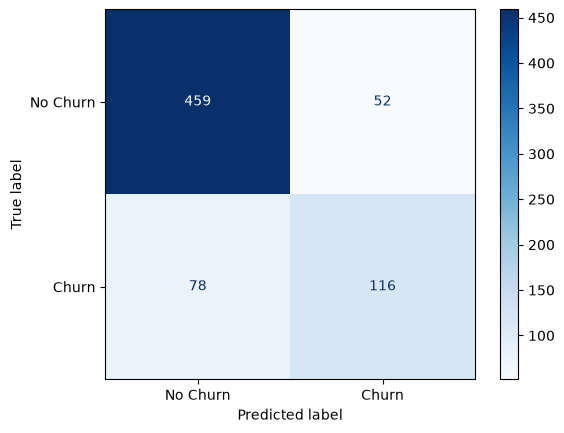

In [27]:
# plot confusion matrix of the best model
from sklearn.metrics import ConfusionMatrixDisplay
best_model = best_models['Logistic Regression']
y_pred = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
disp.plot(cmap=plt.cm.Blues)
plt.show()  #  [TN, FP]
            #  [FN, TP]

<div style="background-color: black; color:white; padding: 20px">

<h2>12- Feature importance of the best models</h2>
</div>

In [28]:
print(best_model.named_steps)

{'standardscaler': StandardScaler(), 'logisticregression': LogisticRegression(C=1)}


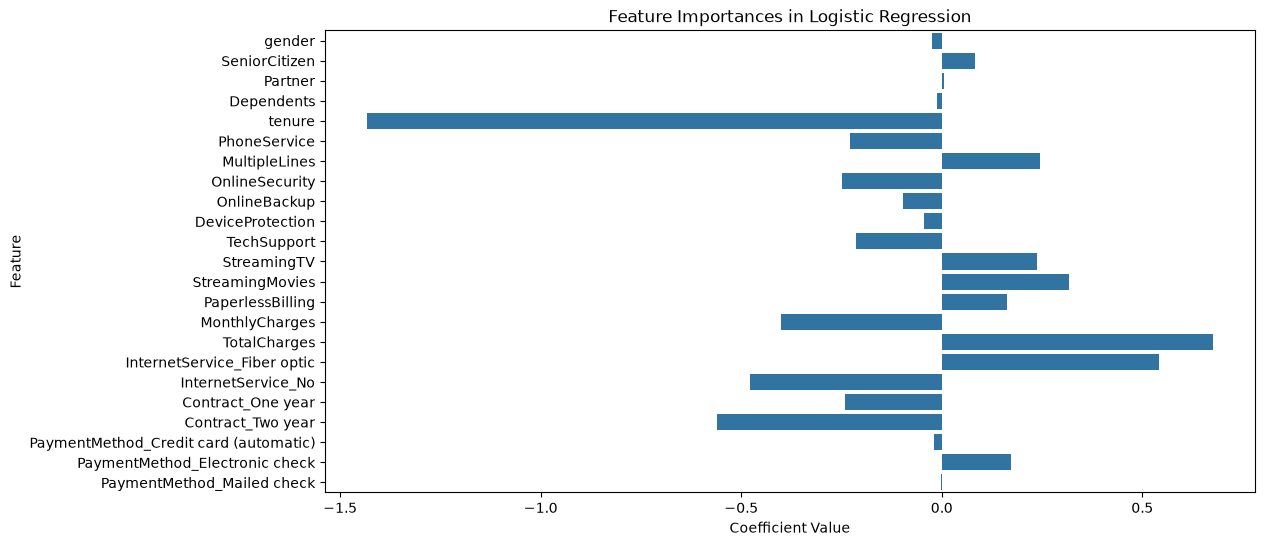

In [29]:
# Extract feature importance (coefficients) and plot them
coefficients = best_model.named_steps['logisticregression'].coef_[0]
features = X.columns

# Plot feature importances
plt.figure(figsize=(12, 6))
sns.barplot(x=coefficients, y=features)
plt.title("Feature Importances in Logistic Regression")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.show()


<div style="background-color: khaki; color:black; padding: 20px">

<h3><b>Positive coefficient</b> → increases the probability of the positive class (Churn = Yes).</h3>
<h3><b>Negative coefficient</b> → decreases the probability of churn.</h3>
<h3><b>Larger absolute value</b> → stronger effect on the model's prediction.</h3>
</div>

<div style="background-color: black; color:white; padding: 20px">

<h2>13- Top 10 features ranked</h2>
</div>

                       Feature  Importance
0                       tenure   -1.239089
1               MonthlyCharges   -0.941830
2  InternetService_Fiber optic    0.786409
3            Contract_Two year   -0.585971
4                 TotalCharges    0.513646
5              StreamingMovies    0.406843
6                  StreamingTV    0.405738
7           InternetService_No   -0.370719
8            Contract_One year   -0.284409
9                MultipleLines    0.284257


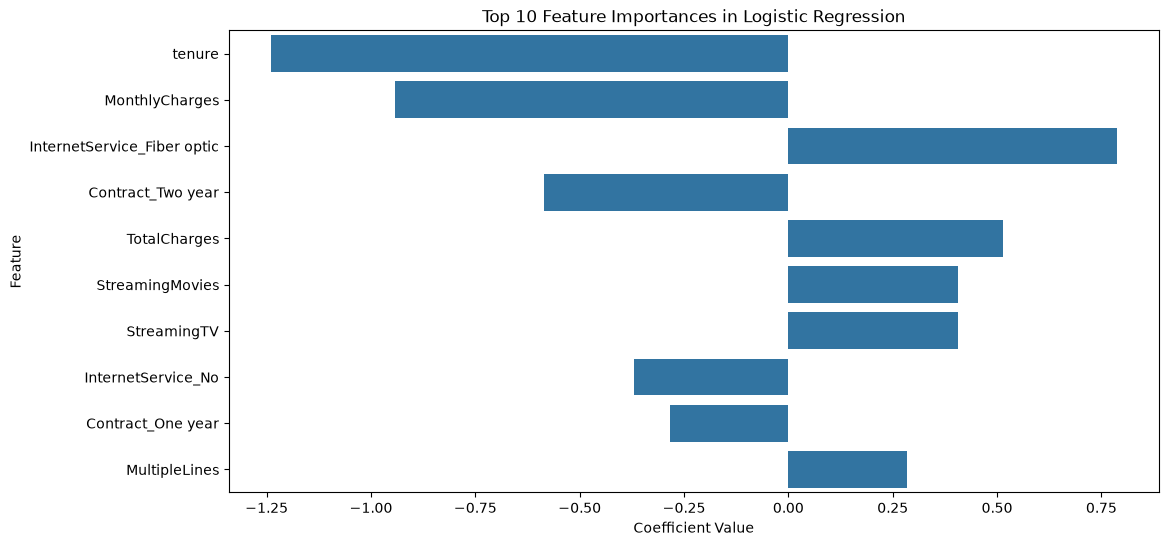

In [30]:

# Extract feature importance (coefficients) and create a DataFrame
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Importance': logreg.coef_[0]
})

# Rank the top 10 features by absolute importance
top_10_features = coefficients.reindex(coefficients['Importance'].abs().sort_values(ascending=False).index).head(10)
top_10_features.reset_index(drop=True, inplace=True)

# Display the top 10 features
print(top_10_features)

# Plot the top 10 features
plt.figure(figsize=(12, 6))
sns.barplot(x='Importance', y='Feature', data=top_10_features)
plt.title("Top 10 Feature Importances in Logistic Regression")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.show()

<div style="background-color: black; color:white; padding: 20px">

<h2>14- Interpretation</h2>

</div>

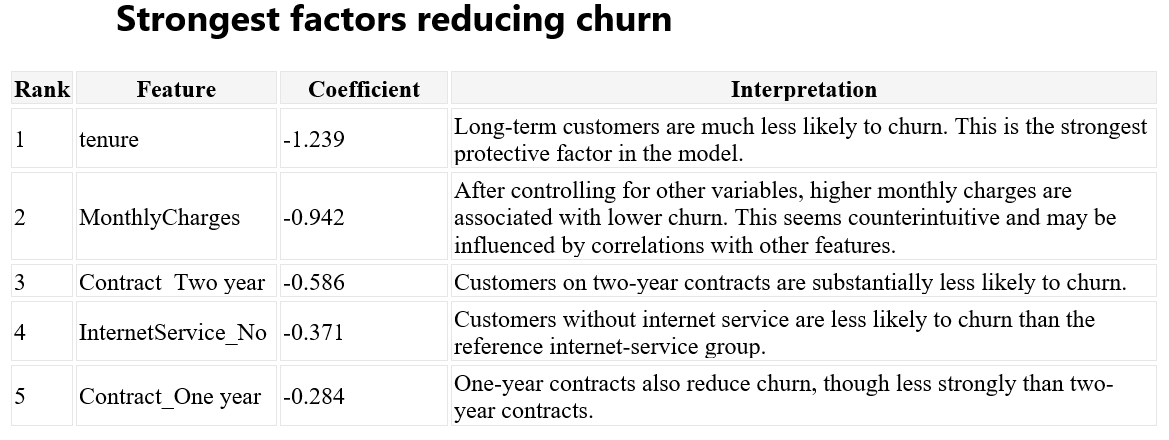

<div style="background-color: maroon; color:white; padding: 20px">
<h2>Business insight</h2>

<p>The most important customer retention signals are:</p>

<p>1. Customer tenure</p>
<p>2. Long-term contracts</p>
<p>3. Not having internet service</p>

This suggests churn is primarily a problem among newer customers and customers with more flexible plans.
</div>

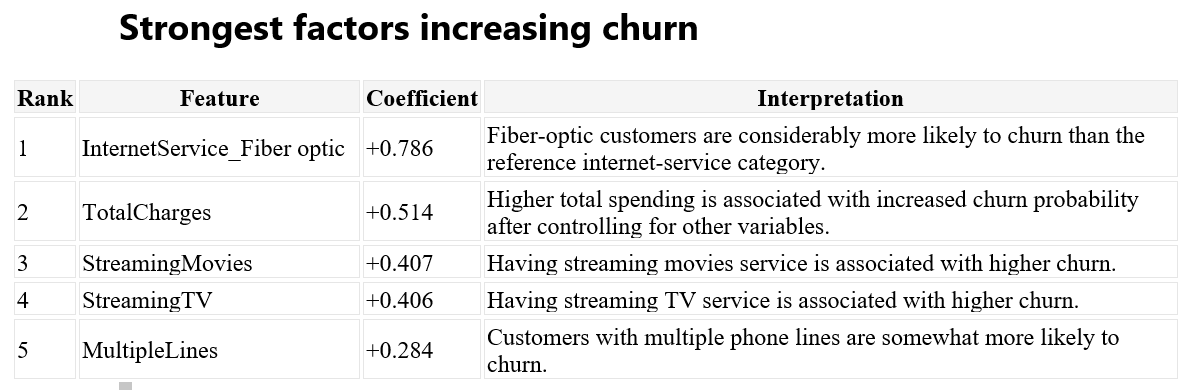

<div style="background-color: maroon; color:white; padding: 20px">
<h2>Business insight</h2>

<p>The strongest churn-risk signals are::</p>

<p>1. Fiber-optic internet</p>
<p>2. High accumulated spending</p>
<p>3. Streaming services</p>
<p>4. Multiple lines</p>

A possible interpretation is that customers using more advanced or premium services may have more competing alternatives and therefore switch providers more often.
</div>


<div style="background-color: black;color:white; padding: 10px;">
<h2>15- Feature Engineering on the negative coefficients</h2>
<p>Square the top two important features for decreasing churn</p>
<p>Tenure ** 2</p>
<p>MonthlyCharges ** 2</p>
</div>

In [31]:
# We already have the X feature matrix after converting categorical columns to dummies
# copy X feature matrix to Xe and y target vector to ye
Xe0 = X.copy()
ye0 = y.copy()

In [32]:
# feature engineering, 'Tenure' squared and 'MonthlyCharges' squared
Xe0['tenure_squared'] = Xe0['tenure'] ** 2
Xe0['MonthlyCharges_squared'] = Xe0['MonthlyCharges'] ** 2

In [33]:
# check columns of Xe
Xe0.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'PaperlessBilling', 'MonthlyCharges', 'TotalCharges',
       'InternetService_Fiber optic', 'InternetService_No',
       'Contract_One year', 'Contract_Two year',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check',
       'tenure_squared', 'MonthlyCharges_squared'],
      dtype='str')

In [34]:
# Splitting the dataset into train and test portions
from sklearn.model_selection import train_test_split
Xe0_train, Xe0_test, ye0_train, ye0_test = train_test_split(Xe0, ye0, test_size=0.2, random_state=42, stratify= y)

In [35]:
# scale the data
from sklearn.preprocessing import StandardScaler
# Initialize the scaler
scaler = StandardScaler()

# Fit and transform the training data
Xe0_train = scaler.fit_transform(Xe0_train)

# Transform the test data using the same scaler
Xe0_test = scaler.transform(Xe0_test)

<div style=" background-color: beige; color:black; padding: 10px;">
<h3> Training the best model with the best parameters on the dataset with engineered features to predict 'No Churn' better</h3>
</div>


In [36]:
from sklearn.metrics import accuracy_score, classification_report

# Initialize and train the logistic regression model
logreg = LogisticRegression(C= 1, max_iter=100, solver='lbfgs')
logreg.fit(Xe0_train, ye0_train)

# Predict on the test set
ye0_pred = logreg.predict(Xe0_test)
accuracy = accuracy_score(ye0_test, ye0_pred)
print(f"Test Accuracy:", accuracy )
print(classification_report(ye0_test, ye0_pred, target_names=['No churn', 'churn']))

Test Accuracy: 0.8041163946061036
              precision    recall  f1-score   support

    No churn       0.84      0.90      0.87      1035
       churn       0.66      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409



<div style="background-color: black;color:white; padding: 10px;">
<h2>16- Feature Engineering on the positive coefficients</h2>
<p>Multiply some important features for increasing churn</p>
<p>InternetService_Fiber optic * TotalCharges</p>
<p>StreamingMovies * TotalCharges</p>
<p>StreamingTV * TotalCharges</p>
</div>

In [37]:
# We already have the X feature matrix after converting categorical columns to dummies
# copy X feature matrix to Xe and y target vector to ye
Xe1 = X.copy()
ye1 = y.copy()

In [38]:
# feature engineering, 'InternetService_Fiber optic', 'StreamingMovies', and 'StreamingTV' multiplied by 'TotalCharges'
Xe1['InternetService_Fiber optic_multiplied'] = Xe1['InternetService_Fiber optic'] * Xe1['TotalCharges']
Xe1['StreamingMovies_multiplied'] = Xe1['StreamingMovies'] * Xe1['TotalCharges']
Xe1['StreamingTV_myltiplied'] = Xe1['StreamingTV'] * Xe1['TotalCharges']

In [39]:
Xe1.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'PaperlessBilling', 'MonthlyCharges', 'TotalCharges',
       'InternetService_Fiber optic', 'InternetService_No',
       'Contract_One year', 'Contract_Two year',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check',
       'InternetService_Fiber optic_multiplied', 'StreamingMovies_multiplied',
       'StreamingTV_myltiplied'],
      dtype='str')

In [40]:
# Splitting the dataset into train and test portions
from sklearn.model_selection import train_test_split
Xe1_train, Xe1_test, ye1_train, ye1_test = train_test_split(Xe1, ye1, test_size=0.2, random_state=42, stratify= y)

In [41]:
# scale the data
from sklearn.preprocessing import StandardScaler
# Initialize the scaler
scaler = StandardScaler()

# Fit and transform the training data
Xe1_train = scaler.fit_transform(Xe1_train)

# Transform the test data using the same scaler
Xe1_test = scaler.transform(Xe1_test)

<div style=" background-color: beige; color:black; padding: 10px;">
<h3> Training the best model with the best parameters on the dataset with engineered features to predict 'Churn' better</h3>
</div>


In [42]:
from sklearn.metrics import accuracy_score, classification_report

# Initialize and train the logistic regression model
logreg = LogisticRegression(C= 1, max_iter=100, solver='lbfgs')
logreg.fit(Xe1_train, ye1_train)

# Predict on the test set
ye1_pred = logreg.predict(Xe1_test)
accuracy = accuracy_score(ye1_test, ye1_pred)
print(f"Test Accuracy:", accuracy )
print(classification_report(ye1_test, ye1_pred, target_names=['No churn', 'churn']))

Test Accuracy: 0.7991483321504613
              precision    recall  f1-score   support

    No churn       0.84      0.89      0.87      1035
       churn       0.65      0.54      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



<div style="background-color: black;color:white; padding: 10px;">
<h2>17- Feature Engineering: Aggregation of services</h2>
<p>Sum the number of services each customer recieves to account for customer engagement.</p>
</div>

In [43]:
# We already have the X feature matrix after converting categorical columns to dummies
# copy X feature matrix to Xa and y target vector to ya
Xa = X.copy()
ya = y.copy()

In [44]:
# aggregate all services and drop the individual services
services = [
    'PhoneService',
    'MultipleLines',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

Xa['NumServices'] = (
    (Xa[services] == 'Yes')
    .sum(axis=1)
)
Xa.drop(columns= services, inplace= True)
Xa.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PaperlessBilling', 'MonthlyCharges', 'TotalCharges',
       'InternetService_Fiber optic', 'InternetService_No',
       'Contract_One year', 'Contract_Two year',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check',
       'NumServices'],
      dtype='str')

In [45]:
# Splitting the dataset into train and test portions
from sklearn.model_selection import train_test_split
Xa_train, Xa_test, ya_train, ya_test = train_test_split(Xa, ya, test_size=0.2, random_state=42, stratify= y)

In [46]:
# scale the data
from sklearn.preprocessing import StandardScaler
# Initialize the scaler
scaler = StandardScaler()

# Fit and transform the training data
Xa_train = scaler.fit_transform(Xa_train)

# Transform the test data using the same scaler
Xa_test = scaler.transform(Xa_test)


<div style=" background-color: beige; color:black; padding: 10px;">
<h3> Training the best model with the best parameters on the dataset with aggregated services</h3>
</div>

In [47]:
from sklearn.metrics import accuracy_score, classification_report

# Initialize and train the logistic regression model
logreg = LogisticRegression(C= 1, max_iter=100, solver='lbfgs')
logreg.fit(Xa_train, ya_train)

# Predict on the test set
ya_pred = logreg.predict(Xa_test)
accuracy = accuracy_score(ya_test, ya_pred)
print(f"Test Accuracy:", accuracy )
print(classification_report(ya_test, ya_pred, target_names=['No churn', 'churn']))

Test Accuracy: 0.794180269694819
              precision    recall  f1-score   support

    No churn       0.84      0.89      0.86      1035
       churn       0.63      0.53      0.58       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.79      0.79      1409

